<span style=float:center><img src='../../lsa-saf/img/LSASAF_Name_Colour.png' alt='LSA SAF' align='right' width='20%'></img>
<span style=float:center><img src='../../lsa-saf/img/eumet_logo.png' alt='Eumetsat logo' align='center' width='30%'></img>

<div class="alert alert-block alert-success">
<b>PREREQUISITE </b><br>
    
To ensure a smooth experience, please note the following requirements and data availability:
* **User Knowledge**: Familiarity with Python and commonly used data science libraries is expected.
* **MSG FRPPixel** data are readily available from the [LSA SAF data server](https://datalsasaf.lsasvcs.ipma.pt/PRODUCTS/MSG/FRP-PIXEL/HDF5/2025/08/) in the `HDF5` format 

</div>


<hr>

# LSA SAF Fire Radiative Power - Utilizing MSG data

#### **About**

Southern Europe is highly susceptible to large wildfires, which can have severe socio-economic and ecological consequences. The Mediterranean climate, characterized by hot, dry summers and mild, wet winters, creates favorable conditions for the outbreak and rapid spread of fires, exacerbated by factors such as drought, high temperatures, and strong winds. Therefore, a reliable detection of fires as well as an estimation of their severity and impact is of great importance when addressing the risk posed by wildfires.

This Jupyter Notebook (JN) aims to analyze Fire Radiative Power (FRP) data measured by SEVIRI onboard Meteosat Second Generation (MSG)
For more information on the SEVIRI dataset, refer to the LSA SAF FRP Pixel Product documentation [LSA SAF FRPPixel [502]](https://landsaf.ipma.pt/en/data/products/fire-products/).

#### **How to Access the Data**

In this example, Fire Radiative Power (FRP) measurements for August 2025 need to be obtained. The FRPPixel is disseminated as 
* `HDF5` file for MSG


The LSA SAF products files can be downloaded from the [data server](https://datalsasaf.lsasvcs.ipma.pt/PRODUCTS/) available at https://datalsasaf.lsasvcs.ipma.pt/ with prior registration. As of September 2025, MSG-based products and pre-operational MTG-based products (Albedo and Land Surface Temperature) are available.

Data can be downloaded in various ways, for instance manually, using approach published on the [lsasaf_data_access GitLab](https://gitlab.com/helpdesk.landsaf/lsasaf_data_access/-/blob/main/examples/webdav/webdav_colab_example.ipynb) repository or using [WebDAV protocol](https://gitlab.com/helpdesk.landsaf/lsasaf_data_access/-/wikis/data/webdav). An additional option is to use the `GNU Wget` program.

#### Basic facts on the LSA SAF FRPPixel (MSG)
> **Product number**: LSA-502
>
> **Spatial resolution**: 3km at nadir
> 
> **Spatial coverage**: MSG-Disk
> 
> **Time steps**: 15 min
> 
> **Data availability**: from 2016
> 


<hr>

#### **Load required libraries**

In [1]:
import h5py as h5                     # a library for working with HDF5 file formats.
import numpy as np                    # a library that lets us work with arrays; we import this with a new name "np"
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
import pandas as pd                   # a library for time series analysis
import geopandas as gpd
import datetime as dt                 # a library that allows us to work with dates and times
import xarray as xr                   # a library that helps us work efficiently with multi-dimensional arrays
import matplotlib.pyplot as plt       # a library the provides plotting capability
from tqdm import tqdm                 # a library to display progress meter with low overhead

from scipy import interpolate
from scipy.ndimage import zoom
import sys
import os
import shutil
import glob 

import cartopy.crs as ccrs  
import cartopy.feature as cf
import cartopy.io.img_tiles as cimgt

from matplotlib.colors import BoundaryNorm, ListedColormap
#testing of this libraries
#import rasterio as rio
import xarray as xr

import matplotlib.pyplot as plt

#for making unions of 
from geopandas.tools import sjoin
from datetime import datetime
import pyproj

from shapely.geometry import Polygon
from shapely.ops import polygonize

import warnings
from cartopy.io import DownloadWarning
warnings.filterwarnings("ignore", category=DownloadWarning)

from utility_functions import *

### <a id='First'></a>1. **Accessing the Data**

We first define the directories for the MSG FRP data, MTG FRP data and fire polygons. Using the `glob` library, we then create lists of all available FRP pixel estimates for both MSG and MTG datasets. These file lists will be used later for data loading, filtering, and comparative analyses.

In [2]:
pathMSG = '../../data/FRP-PIXEL/'


MSG_Frp_files = glob.glob(pathMSG+'HDF5_LSASAF_MSG_FRP-PIXEL-ListProduct_MSG-Disk_*')


Here we demonstrate how to read a single MSG FRPPixel file. The function `readFRP_list` loads selected variables from the first file in the list and returns the extracted data as a pandas DataFrame.

In [3]:
# # save TIME - DO NOT RUN this cell (data have been pre-prepared)!!
# # We read MSG all the necesary parts of data into the dataframe

firstFile = True
for datafile in MSG_Frp_files:
     print(datafile)
     if firstFile:
         msg_frp_df = readFRP_list(datafile, 'FRP','FRP_UNCERTAINTY','LATITUDE','LONGITUDE' ,'FIRE_CONFIDENCE','PIXEL_SIZE',group=False)
         firstFile = False
     else:
         b = readFRP_list(datafile, 'FRP','FRP_UNCERTAINTY','LATITUDE','LONGITUDE' ,'FIRE_CONFIDENCE','PIXEL_SIZE',group=False)
         msg_frp_df = pd.concat([msg_frp_df, b], axis= 0)

../../data/FRP-PIXEL/HDF5_LSASAF_MSG_FRP-PIXEL-ListProduct_MSG-Disk_202108052000
argument FRP
scaling factor:  10.0 Units: MW
argument FRP_UNCERTAINTY
scaling factor:  100.0 Units: MW
argument LATITUDE
scaling factor:  100.0 Units: Degree
argument LONGITUDE
scaling factor:  100.0 Units: Degree
argument FIRE_CONFIDENCE
scaling factor:  100.0 Units: p.n.
argument PIXEL_SIZE
scaling factor:  100.0 Units: Km
../../data/FRP-PIXEL/HDF5_LSASAF_MSG_FRP-PIXEL-ListProduct_MSG-Disk_202108051245
argument FRP
scaling factor:  10.0 Units: MW
argument FRP_UNCERTAINTY
scaling factor:  100.0 Units: MW
argument LATITUDE
scaling factor:  100.0 Units: Degree
argument LONGITUDE
scaling factor:  100.0 Units: Degree
argument FIRE_CONFIDENCE
scaling factor:  100.0 Units: p.n.
argument PIXEL_SIZE
scaling factor:  100.0 Units: Km
../../data/FRP-PIXEL/HDF5_LSASAF_MSG_FRP-PIXEL-ListProduct_MSG-Disk_202108050845
argument FRP
scaling factor:  10.0 Units: MW
argument FRP_UNCERTAINTY
scaling factor:  100.0 Units: MW


### <a id='Third'></a>3. **High confidence FRP data statistics**


Only pixels with fire confidence level exceeding 90% are considered:

In [4]:
## Filter out all data with FIRE CONFIDENCE below treshold
msg_frp_df_conf90 = msg_frp_df.loc[msg_frp_df['FIRE_CONFIDENCE'] >= 0.9].copy() 



#### **Daily FRP values for DAY X**

We will select only the records from the datasets that correspond to a given day. We can then further explore the data, for example by printing the first few rows with `head()` or by generating summary statistics with `describe()`.

In [5]:
msg_frp_df_conf90['DAY'] = msg_frp_df_conf90['TIME'].dt.day
msg_frp_df_conf90['HOUR'] = msg_frp_df_conf90['TIME'].dt.hour


<div class="alert alert-block alert-success"> 
To display data for a specific day, replace <code>X</code> in the next cell with the desired day number:
<br>
<br> msg_frp_15 = msg_frp_df_conf90.loc[msg_frp_df_conf90['DAY'] == <code>X</code>].copy() </div>

In [6]:
msg_frp_15 = msg_frp_df_conf90.loc[msg_frp_df_conf90['DAY']==5].copy()


In this step, the datasets are prepared for grouping by geographic coordinates.

First, the LATITUDE and the LONGITUDE values are rounded to three decimal places. This slightly reduces precision but simplifies the grouping process. Then, a combined LATLON column is created that stores each pixel’s latitude–longitude pair (this step may not be strictly necessary).

Finally, the data is then grouped by the rounded latitude and longitude, and for each grid point, the maximum FRP value is calculated. The resulting grouped dataset is stored in a new dataframe, and the first few rows are displayed to verify successful processing.

In [7]:
# MSG rounded latitude and longitude for easier grouping
msg_frp_15['LATITUDE'] = msg_frp_15['LATITUDE'].round(3)
msg_frp_15['LONGITUDE'] = msg_frp_15['LONGITUDE'].round(3)

msg_frp_15_m = msg_frp_15.groupby(['LATITUDE','LONGITUDE'])['FRP'].max().reset_index()
print(msg_frp_15_m.head())

   LATITUDE  LONGITUDE    FRP
0    -30.45      29.65  228.5
1    -30.20      29.43  160.8
2    -30.20      29.47  294.7
3    -30.16      29.42  354.5
4    -30.16      29.46  407.7


We define a Plate Carrée cartographic projection with the central meridian set to 0° (central_longitude = 0.0) is defined. A figure is created with two subplots, positioned side by side, each using the defined projection.



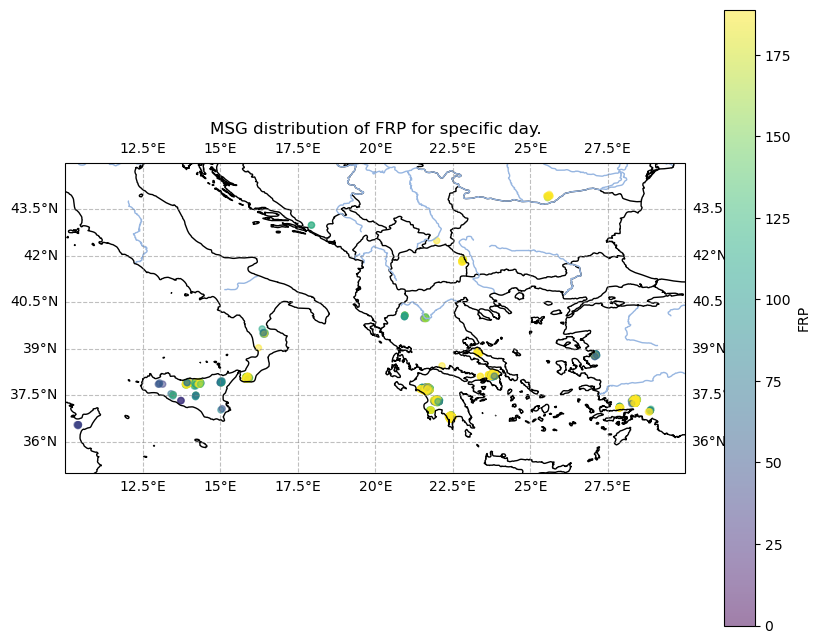

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

choosen_projection = ccrs.PlateCarree(central_longitude=0.0)

# Limit c value using the 75th percentile
msg_75percentile = msg_frp_15['FRP'].quantile(q=0.75)

# Create a single-plot figure
fig, ax = plt.subplots(subplot_kw={'projection': choosen_projection}, figsize=(10, 8))

# Plot MTG data only
msg_frp_15.plot.scatter(
    ax=ax,
    x='LONGITUDE', y='LATITUDE',
    c='FRP', cmap='viridis',
    alpha=0.5,
    xlabel='LON', ylabel='LAT',
    clim=(0, msg_75percentile),
    title='MSG distribution of FRP for specific day.'
)

# Add map features
ax.add_feature(cf.BORDERS)
ax.add_feature(cf.RIVERS)
ax.coastlines()
ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5)
#Iberian Peninsula:
#ax.set_extent([-10, 3, 35, 45], crs=ccrs.PlateCarree())
#Global
#ax.set_extent([-65, 50, -35, 55], crs=ccrs.PlateCarree())
#Mediterranean
ax.set_extent([10, 30, 35, 45], crs=ccrs.PlateCarree())
plt.show()


#### References:

* array Developers (2023). xarray User Guide. [https://docs.xarray.dev/en/stable/user-guide/index.html](https://docs.xarray.dev/en/stable/user-guide/index.html). Accesed: 11.9.2025
* Met Office (2010-2015). Cartopy: a cartographic python library with a Matplotlib interface. https://scitools.org.uk/cartopy. Accessed: 20.11.2023.